In [5]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})


def shape(a, b, c, d, x):
    """Trapezoid fuzzy set: rises from a to b, stays at 1 until c, falls to d."""
    up = (x >= a).astype(float) if b == a else (x - a) / (b - a)
    down = (x <= d).astype(float) if d == c else (d - x) / (d - c)
    return np.clip(np.minimum(up, down), 0, 1)

## Money range membership function

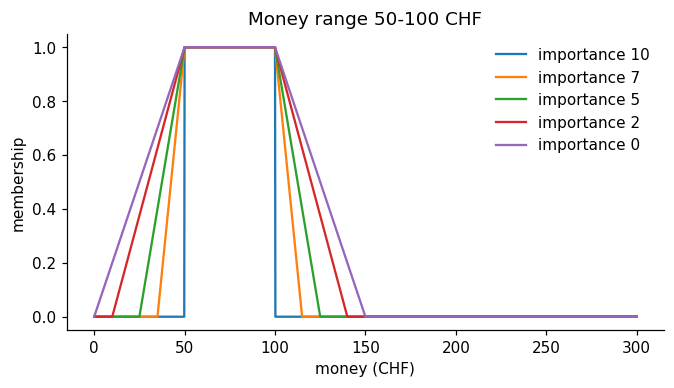

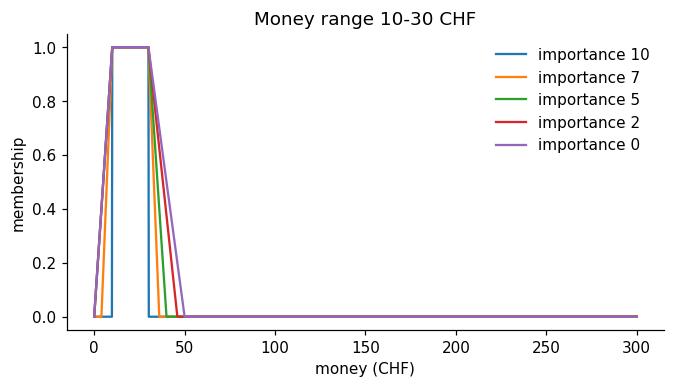

In [6]:
MONEY = np.linspace(0, 300, 1501)    # money axis in CHF

MONEY_SOFTNESS = 1.0   # how wide the slopes get at importance 0 (1.0 = as wide as the range)


def money_membership(max_money, importance, min_money=0, x=MONEY):
    """Fuzzy set for 'how much I want to spend', on the grid x (in CHF).

    max_money   upper end of the range
    min_money   lower end of the range (default 0)
    importance  0-10: 10 = crisp rectangle, 0 = very soft slopes
    """
    importance = float(np.clip(importance, 0, 10))
    softness = (10 - importance) / 10                         # 0 = crisp, ..., 1 = very soft slope
    w = softness * MONEY_SOFTNESS * (max_money - min_money)   # width of each slope

    a = max(min_money - w, 0)
    b = min_money
    c = max_money
    d = max_money + w
    return shape(a, b, c, d, x)


# Plot 1
fig, ax = plt.subplots(figsize=(7, 3.5))
for imp in [10, 7, 5, 2, 0]:
    ax.plot(MONEY, money_membership(100, imp, 50), label=f'importance {imp}')
ax.set_xlabel('money (CHF)')
ax.set_ylabel('membership')
ax.set_title('Money range 50-100 CHF')
ax.legend(frameon=False)
plt.show()

# Plot 2
fig, ax = plt.subplots(figsize=(7, 3.5))
for imp in [10, 7, 5, 2, 0]:
    ax.plot(MONEY, money_membership(30, imp, 10), label=f'importance {imp}')
ax.set_xlabel('money (CHF)')
ax.set_ylabel('membership')
ax.set_title('Money range 10-30 CHF')
ax.legend(frameon=False)
plt.show()

## Group size membership function

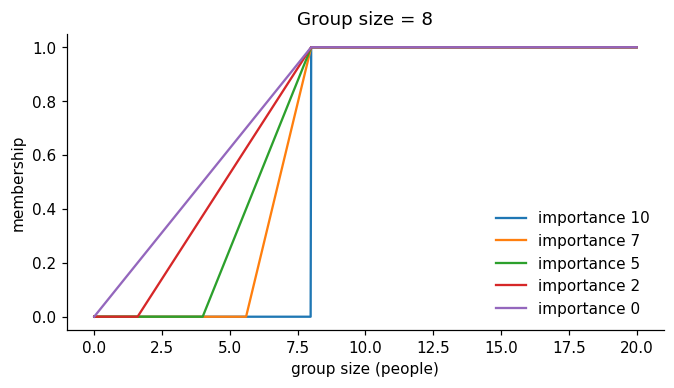

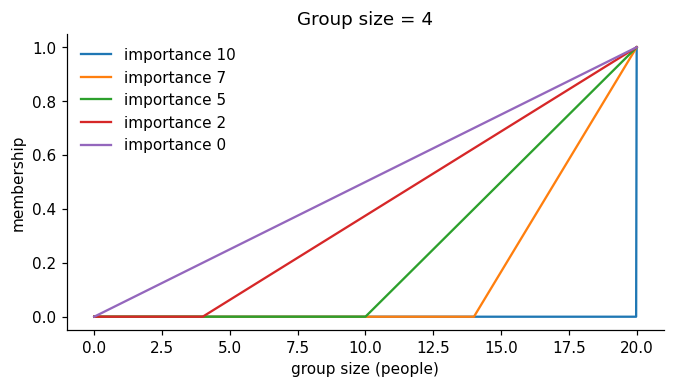

In [ ]:
PEOPLE = np.linspace(0, 20, 1001)    # group size axis in people

GROUP_SOFTNESS = 1.0   # how far left the ramp starts at importance 0 (1.0 = starts at 0)


def group_membership(size, importance, x=PEOPLE):
    """Fuzzy set for 'a group of at least this size', on the grid x (in people).

    size        the group size (number of people)
    importance  0-10: 10 = crisp step (rectangle), 0 = very soft ramp
    """
    importance = float(np.clip(importance, 0, 10))
    softness = (10 - importance) / 10          # 0 = crisp, ..., 1 = very soft ramp
    w = softness * GROUP_SOFTNESS * size       # width of the rising side

    a = max(size - w, 0)    # the ramp starts here (not below 0)
    b = size                # from here on the membership is 1
    top = x.max()           # c = d = end of the axis, so it stays at 1 forever
    return shape(a, b, top, top, x)


# Plot 3
fig, ax = plt.subplots(figsize=(7, 3.5))
for imp in [10, 7, 5, 2, 0]:
    ax.plot(PEOPLE, group_membership(8, imp), label=f'importance {imp}')
ax.set_xlabel('group size (people)')
ax.set_ylabel('membership')
ax.set_title('Group size = 8')
ax.legend(frameon=False)
plt.show()

# Plot 4
fig, ax = plt.subplots(figsize=(7, 3.5))
for imp in [10, 7, 5, 2, 0]:
    ax.plot(PEOPLE, group_membership(4, imp), label=f'importance {imp}')
ax.set_xlabel('group size (people)')
ax.set_ylabel('membership')
ax.set_title('Group size = 4')
ax.legend(frameon=False)
plt.show()